# 03 팀 모델 B — 로그 멜 스펙트로그램 CNN (처음부터 학습)

- 입력: 1초 녹음 → 로그 멜 스펙트로그램 (1 × 64 × 101), `torchaudio.transforms.MelSpectrogram` + `AmplitudeToDB`
- 구조: [합성곱 3×3 + 배치 정규화 + ReLU + 최대 풀링] × 4 (채널 16 → 32 → 64 → 128) → 전역 평균 풀링 → Linear(128 → 35). 교재 4장 CNN 분류기를 소리 그림에 적용
- 사전 학습 없이 우리 학습 묶음만으로 배움. 기준선 A(02 노트북)와의 비교가 목적
- 스펙트로그램은 학습·검증 녹음 전체에 대해 한 번만 계산해 `cache/`에 저장하고 GPU에 올려 학습 (에폭마다 파일을 다시 읽지 않음)
- 모델 선택은 검증 정확도로 하고 시험 묶음은 쓰지 않습니다
- Colab: 런타임 유형 T4 GPU → 모두 실행. `SMOKE = True`는 단어마다 몇 개만 써서 끝까지 도는지만 확인

In [1]:
# 셀 1. 설정과 버전
import os, sys, time, random, collections, copy
import numpy as np
import torch
import torch.nn as nn
import torchaudio
import soundfile as sf
import matplotlib.pyplot as plt

SMOKE = False                  # True: 단어마다 학습 20개·검증 5개, 1에폭
SEED = 0
DATA_ROOT = "data"
CACHE_DIR = "cache"
SR = 16000
N_FFT, HOP, N_MELS = 400, 160, 64
CHANNELS = [16, 32, 64, 128]   # 블록마다 채널
EPOCHS = 20
BATCH = 256
LR = 1e-3

random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
if SMOKE:
    EPOCHS = 1
print("python", sys.version.split()[0], "| torch", torch.__version__, "| torchaudio", torchaudio.__version__, "| soundfile", sf.__version__)
print("device:", device, "|", torch.cuda.get_device_name(0) if device.type == "cuda" else "GPU 없음 → CPU", "| SMOKE", SMOKE)

python 3.13.16 | torch 2.14.1+cu130 | torchaudio 2.11.0+cu130 | soundfile 0.14.0
device: cuda | Tesla T4 | SMOKE False


In [2]:
# 셀 2. 데이터와 공식 분할 (02 노트북과 같음, 시험 묶음은 불러오지 않음)
os.makedirs(DATA_ROOT, exist_ok=True)
splits = {s: torchaudio.datasets.SPEECHCOMMANDS(DATA_ROOT, download=True, subset=sub)
          for s, sub in [("train", "training"), ("val", "validation")]}
BASE_DIR = os.path.dirname(splits["train"]._path)

items = {s: [] for s in splits}
for s, ds in splits.items():
    for i in range(len(ds)):
        path, _, word, _, _ = ds.get_metadata(i)
        items[s].append((path, word))
WORDS = sorted({w for p, w in items["train"]})
W2I = {w: i for i, w in enumerate(WORDS)}

if SMOKE:
    for s, k in [("train", 20), ("val", 5)]:
        per = collections.defaultdict(list)
        for it in items[s]:
            per[it[1]].append(it)
        items[s] = [it for w in WORDS for it in per[w][:k]]
print({s: len(v) for s, v in items.items()}, "| 단어", len(WORDS))

100%|██████████| 2.26G/2.26G [00:23<00:00, 103MB/s]


{'train': 84843, 'val': 9981} | 단어 35


In [3]:
# 셀 3. 로그 멜 스펙트로그램을 한 번만 계산해 저장
mel = torchaudio.transforms.MelSpectrogram(sample_rate=SR, n_fft=N_FFT, hop_length=HOP, n_mels=N_MELS).to(device)
to_db = torchaudio.transforms.AmplitudeToDB(stype="power", top_db=80).to(device)

class Wavs(torch.utils.data.Dataset):
    def __init__(self, items):
        self.items = items
    def __len__(self):
        return len(self.items)
    def __getitem__(self, i):
        path, word = self.items[i]
        x, _ = sf.read(os.path.join(BASE_DIR, path), dtype="float32")
        x = torch.from_numpy(x)
        return torch.nn.functional.pad(x, (0, max(0, SR - len(x))))[:SR], W2I[word]

def make_mels(split):
    path = os.path.join(CACHE_DIR, f"mel{N_MELS}_{split}{'_smoke' if SMOKE else ''}.pt")
    if os.path.exists(path):
        d = torch.load(path)
        print(f"{split}: 저장된 스펙트로그램 사용 {tuple(d['X'].shape)} (처음 계산 {d['sec']:.0f}초)")
        return d
    loader = torch.utils.data.DataLoader(Wavs(items[split]), batch_size=256, num_workers=2 if os.name != "nt" else 0)
    X, Y = [], []
    t0 = time.time()
    with torch.no_grad():
        for x, y in loader:
            X.append(to_db(mel(x.to(device))).half().cpu())      # (B, 64, 101)
            Y.append(y)
    d = {"X": torch.cat(X).unsqueeze(1), "Y": torch.cat(Y), "sec": time.time() - t0}   # (N, 1, 64, 101)
    os.makedirs(CACHE_DIR, exist_ok=True)
    torch.save(d, path)
    print(f"{split}: {tuple(d['X'].shape)}를 {d['sec']:.0f}초에 계산 → {path}")
    return d

data = {s: make_mels(s) for s in ["train", "val"]}
MEL_SEC = sum(d["sec"] for d in data.values())
MU = data["train"]["X"].float().mean().item()            # 학습 묶음 통계로 표준화
SD = data["train"]["X"].float().std().item()
print(f"학습 묶음 평균 {MU:.2f} dB, 표준편차 {SD:.2f} dB")

train: (84843, 1, 64, 101)를 26초에 계산 → cache/mel64_train.pt
val: (9981, 1, 64, 101)를 7초에 계산 → cache/mel64_val.pt
학습 묶음 평균 -27.29 dB, 표준편차 16.30 dB


In [4]:
# 셀 4. 팀 모델 B 구조
class KWSCNN(nn.Module):
    def __init__(self, channels=CHANNELS, n_classes=35):
        super().__init__()
        blocks, c_in = [], 1
        for c in channels:
            blocks += [nn.Conv2d(c_in, c, 3, padding=1), nn.BatchNorm2d(c), nn.ReLU(inplace=True), nn.MaxPool2d(2)]
            c_in = c
        self.features = nn.Sequential(*blocks)
        self.pool = nn.AdaptiveAvgPool2d(1)               # 전역 평균 풀링: 남은 주파수·시간 칸을 평균
        self.fc = nn.Linear(c_in, n_classes)

    def forward(self, x):
        x = self.pool(self.features(x)).flatten(1)
        return self.fc(x)

model = KWSCNN(n_classes=len(WORDS)).to(device)
n_params = sum(p.numel() for p in model.parameters())
print(f"파라미터 {n_params:,}개 (기준선 A의 wav2vec2 94,370,944개의 {n_params / 94370944:.2%})")

# 블록마다 출력 모양과 파라미터 (구조 그림용)
x = torch.zeros(2, 1, N_MELS, 101, device=device)
print(f"  입력          {tuple(x.shape[1:])}")
for b in range(len(CHANNELS)):
    blk = model.features[4 * b: 4 * b + 4]
    x = blk(x)
    conv = blk[0]
    print(f"  블록 {b + 1} → {tuple(x.shape[1:])}  파라미터 {sum(p.numel() for p in blk.parameters()):>7,}"
          f"  (합성곱 {conv.in_channels}×{conv.out_channels}×9+{conv.out_channels} = {conv.weight.numel() + conv.bias.numel():,}, BN {2 * conv.out_channels})")
x = model.pool(x).flatten(1)
print(f"  전역 평균 풀링 → {tuple(x.shape[1:])}")
print(f"  Linear → {tuple(model.fc(x).shape[1:])}  파라미터 {CHANNELS[-1]}×{len(WORDS)}+{len(WORDS)} = {sum(p.numel() for p in model.fc.parameters()):,}")

파라미터 102,147개 (기준선 A의 wav2vec2 94,370,944개의 0.11%)
  입력          (1, 64, 101)
  블록 1 → (16, 32, 50)  파라미터     192  (합성곱 1×16×9+16 = 160, BN 32)
  블록 2 → (32, 16, 25)  파라미터   4,704  (합성곱 16×32×9+32 = 4,640, BN 64)
  블록 3 → (64, 8, 12)  파라미터  18,624  (합성곱 32×64×9+64 = 18,496, BN 128)
  블록 4 → (128, 4, 6)  파라미터  74,112  (합성곱 64×128×9+128 = 73,856, BN 256)
  전역 평균 풀링 → (128,)
  Linear → (35,)  파라미터 128×35+35 = 4,515


In [5]:
# 셀 5. 평가 지표 (02 노트북과 같음)
def metrics(pred, y, k=len(WORDS)):
    cm = torch.bincount(y * k + pred, minlength=k * k).reshape(k, k).float()
    tp = cm.diag()
    prec = tp / cm.sum(0).clamp(min=1)
    rec = tp / cm.sum(1).clamp(min=1)
    f1 = 2 * prec * rec / (prec + rec).clamp(min=1e-12)
    return (tp.sum() / cm.sum()).item(), f1.mean().item(), cm

Xtr = ((data["train"]["X"].float() - MU) / SD).to(device); Ytr = data["train"]["Y"].to(device)
Xva = ((data["val"]["X"].float() - MU) / SD).to(device);   Yva = data["val"]["Y"].to(device)

def evaluate(m):
    m.eval()
    preds = []
    with torch.no_grad(), torch.autocast(device.type, dtype=torch.float16, enabled=device.type == "cuda"):
        for i in range(0, len(Xva), 1024):
            preds.append(m(Xva[i:i + 1024]).argmax(1))
    return metrics(torch.cat(preds), Yva)

epoch  1  train loss 2.1146 | val acc 0.7001 | val macro F1 0.6504 | 8.1초 (누적 8초)
epoch  2  train loss 0.8434 | val acc 0.6466 | val macro F1 0.6213 | 7.5초 (누적 16초)
epoch  3  train loss 0.5595 | val acc 0.8292 | val macro F1 0.8180 | 7.6초 (누적 24초)
epoch  4  train loss 0.4401 | val acc 0.8402 | val macro F1 0.8252 | 7.7초 (누적 32초)
epoch  5  train loss 0.3705 | val acc 0.8430 | val macro F1 0.8299 | 7.8초 (누적 40초)
epoch  6  train loss 0.3240 | val acc 0.8352 | val macro F1 0.8193 | 7.9초 (누적 48초)
epoch  7  train loss 0.2916 | val acc 0.8603 | val macro F1 0.8449 | 8.0초 (누적 56초)
epoch  8  train loss 0.2631 | val acc 0.8912 | val macro F1 0.8777 | 8.2초 (누적 65초)
epoch  9  train loss 0.2419 | val acc 0.8907 | val macro F1 0.8825 | 8.3초 (누적 73초)
epoch 10  train loss 0.2248 | val acc 0.8574 | val macro F1 0.8607 | 8.3초 (누적 82초)
epoch 11  train loss 0.2101 | val acc 0.8858 | val macro F1 0.8753 | 8.2초 (누적 90초)
epoch 12  train loss 0.1969 | val acc 0.9036 | val macro F1 0.8942 | 8.1초 (누적 99초)
epoch

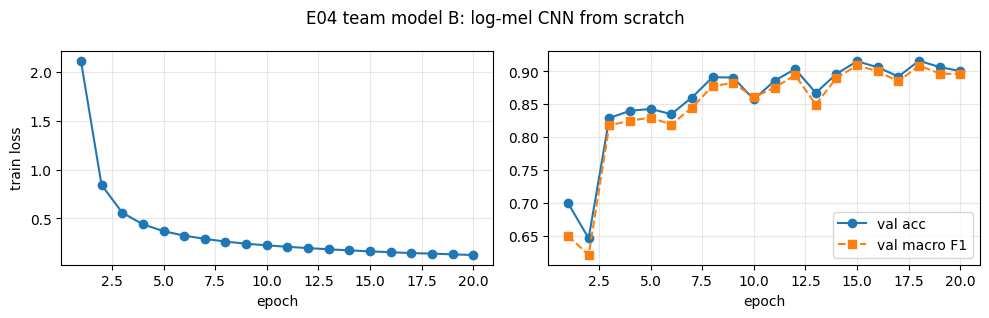

In [6]:
# 셀 6. E04 팀 모델 B 학습 (검증 정확도가 가장 높은 에폭의 모델을 기억)
torch.manual_seed(SEED)
model = KWSCNN(n_classes=len(WORDS)).to(device)
opt = torch.optim.Adam(model.parameters(), lr=LR)
scaler = torch.amp.GradScaler(enabled=device.type == "cuda")
hist, best = [], None
t_start = time.time()
for ep in range(EPOCHS):
    model.train()
    t0 = time.time()
    perm = torch.randperm(len(Xtr), device=device)
    tot = 0.0
    for i in range(0, len(Xtr), BATCH):
        idx = perm[i:i + BATCH]
        with torch.autocast(device.type, dtype=torch.float16, enabled=device.type == "cuda"):
            loss = nn.functional.cross_entropy(model(Xtr[idx]), Ytr[idx])
        opt.zero_grad()
        scaler.scale(loss).backward(); scaler.step(opt); scaler.update()
        tot += loss.item() * len(idx)
    if device.type == "cuda":
        torch.cuda.synchronize()
    sec = time.time() - t0
    acc, f1, cm = evaluate(model)
    hist.append((tot / len(Xtr), acc, f1, sec))
    if best is None or acc > best["acc"]:
        best = {"acc": acc, "f1": f1, "epoch": ep + 1, "cm": cm.cpu(), "state": copy.deepcopy(model.state_dict())}
    print(f"epoch {ep + 1:2d}  train loss {tot / len(Xtr):.4f} | val acc {acc:.4f} | val macro F1 {f1:.4f} | {sec:.1f}초 (누적 {time.time() - t_start:.0f}초)")
TRAIN_SEC = time.time() - t_start
EPOCH_SEC = float(np.mean([h[3] for h in hist]))
print(f"E04 팀 모델 B: 검증 정확도 {best['acc']:.2%}, 매크로 F1 {best['f1']:.4f} (최고 에폭 {best['epoch']}/{EPOCHS})")
print(f"학습 {TRAIN_SEC:.0f}초 (에폭당 학습 {EPOCH_SEC:.1f}초) + 스펙트로그램 계산 {MEL_SEC:.0f}초 (한 번만)")

os.makedirs(CACHE_DIR, exist_ok=True)
torch.save({"state": best["state"], "mu": MU, "sd": SD, "words": WORDS}, os.path.join(CACHE_DIR, f"E04_cnn{'_smoke' if SMOKE else ''}.pt"))
model.load_state_dict(best["state"])

h = np.array(hist)
fig, ax = plt.subplots(1, 2, figsize=(10, 3.2))
ax[0].plot(range(1, len(h) + 1), h[:, 0], "o-"); ax[0].set_xlabel("epoch"); ax[0].set_ylabel("train loss"); ax[0].grid(alpha=.3)
ax[1].plot(range(1, len(h) + 1), h[:, 1], "o-", label="val acc"); ax[1].plot(range(1, len(h) + 1), h[:, 2], "s--", label="val macro F1")
ax[1].set_xlabel("epoch"); ax[1].legend(); ax[1].grid(alpha=.3)
plt.suptitle("E04 team model B: log-mel CNN from scratch"); plt.tight_layout(); plt.show()

In [7]:
# 셀 7. 가장 많이 헷갈린 단어 쌍과 단어별 정확도
cm = best["cm"].clone()
cm.fill_diagonal_(0)
top = torch.topk(cm.flatten(), 10)
print("정답 → 예측 (검증에서 틀린 횟수)")
for v, i in zip(top.values.tolist(), top.indices.tolist()):
    t, p = divmod(i, len(WORDS))
    print(f"  {WORDS[t]:>9s} → {WORDS[p]:<9s} {int(v)}")
per_word = (best["cm"].diag() / best["cm"].sum(1).clamp(min=1)).tolist()
order = np.argsort(per_word)
print("단어별 정확도 낮은 5개:", ", ".join(f"{WORDS[i]} {per_word[i]:.1%}" for i in order[:5]))
print("단어별 정확도 높은 5개:", ", ".join(f"{WORDS[i]} {per_word[i]:.1%}" for i in order[::-1][:5]))

# CPU에서 녹음 1개 추론 시간 (작은 기기 조건 확인용, 워밍업 10번 뒤 100번 평균)
m_cpu = copy.deepcopy(model).float().cpu().eval()
x1 = Xva[:1].float().cpu()
with torch.no_grad():
    for _ in range(10):
        m_cpu(x1)
    t0 = time.perf_counter()
    for _ in range(100):
        m_cpu(x1)
CPU_MS = (time.perf_counter() - t0) / 100 * 1000
print(f"CPU 추론 시간 (녹음 1개, 스펙트로그램 계산 제외): {CPU_MS:.2f} ms")

정답 → 예측 (검증에서 틀린 횟수)
       tree → three     38
         up → off       24
         no → nine      23
         go → no        17
         go → down      15
       bird → nine      14
        one → nine      13
      house → follow    13
      house → yes       12
       down → nine      12
단어별 정확도 낮은 5개: house 73.3%, tree 74.8%, bird 80.2%, wow 82.9%, bed 84.5%
단어별 정확도 높은 5개: nine 98.9%, yes 98.7%, stop 96.0%, eight 96.0%, on 95.9%
CPU 추론 시간 (녹음 1개, 스펙트로그램 계산 제외): 2.84 ms


In [8]:
# 셀 8. 실험 결과 표 (E01~E03은 01·02 노트북 출력)
rows = [
    ("E01", "0번 기준: 가장 많은 단어(zero)만 고름", "0.0385", "0.0021", "-", "01 노트북"),
    ("E02", "기준선 A: wav2vec2-base 12층 고정 + Linear", "0.9019", "0.8937", "특징 140초 + 학습 5.8초 (T4)", "02 노트북"),
    ("E03", "기준선 A의 특징 층만 바꿈: 5층", "0.9541", "0.9511", "층마다 약 5.3초 (T4)", "02 노트북"),
    ("E04", f"팀 모델 B: 로그 멜 CNN {CHANNELS}, 처음부터 학습", f"{best['acc']:.4f}", f"{best['f1']:.4f}",
     f"스펙트로그램 {MEL_SEC:.0f}초 + 학습 {TRAIN_SEC:.0f}초 ({device.type})", f"파라미터 {n_params:,}, CPU {CPU_MS:.2f} ms"),
]
print(f"{'번호':<4} | {'바꾼 설정':<42} | {'검증 정확도':>8} | {'매크로 F1':>8} | {'시간':<30} | 비고")
for r in rows:
    print(" | ".join([r[0].ljust(4), r[1].ljust(42), r[2].rjust(10), r[3].rjust(9), r[4].ljust(32), r[5]]))
print("SMOKE 모드 결과" if SMOKE else f"device {device}, EPOCHS {EPOCHS}, BATCH {BATCH}, LR {LR}, 시드 {SEED}")

번호   | 바꾼 설정                                      |   검증 정확도 |   매크로 F1 | 시간                             | 비고
E01  | 0번 기준: 가장 많은 단어(zero)만 고름                  |     0.0385 |    0.0021 | -                                | 01 노트북
E02  | 기준선 A: wav2vec2-base 12층 고정 + Linear       |     0.9019 |    0.8937 | 특징 140초 + 학습 5.8초 (T4)           | 02 노트북
E03  | 기준선 A의 특징 층만 바꿈: 5층                        |     0.9541 |    0.9511 | 층마다 약 5.3초 (T4)                  | 02 노트북
E04  | 팀 모델 B: 로그 멜 CNN [16, 32, 64, 128], 처음부터 학습 |     0.9162 |    0.9089 | 스펙트로그램 33초 + 학습 166초 (cuda)      | 파라미터 102,147, CPU 2.84 ms
device cuda, EPOCHS 20, BATCH 256, LR 0.001, 시드 0
